# Indian Real Estate Market — Exploratory Data Analysis

**Project:** Data Analysis and Business Insights

**Dataset:** Real Estate Listings Dataset

**Records:** 600

**Features:** 15

**Cities Covered:** 8

**Tools & Technologies:**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Objective

The objective of this project is to explore real-estate listings across multiple Indian cities, identify pricing patterns, compare property categories, detect potential outliers and generate actionable business insights.

## Business Questions

1. Which city has the highest average property price?
2. Which property type is most common?
3. How do property prices vary across cities?
4. What percentage of listings are marked as sold?
5. Are there unusual property prices or data inconsistencies?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r"../../week-3-data-pipeline/data/da_realestate_listings.csv"
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (600, 15)


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [3]:
# Dataset Overview

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe().round(2))

Number of Rows: 600
Number of Columns: 15

Column Names:
['listing_id', 'city', 'locality', 'type', 'area_sqft', 'price_per_sqft', 'total_price_lakh', 'age_years', 'floor', 'parking', 'furnished', 'listed_date', 'days_on_market', 'transaction_type', 'sold']

Data Types:


,Data Type
listing_id,object
city,object
locality,object
type,object
area_sqft,int64
price_per_sqft,int64
total_price_lakh,float64
age_years,int64
floor,int64
parking,int64



Missing Values:


,Missing Values
listing_id,0
city,0
locality,0
type,0
area_sqft,0
price_per_sqft,0
total_price_lakh,0
age_years,0
floor,0
parking,0



Duplicate Records: 0

Statistical Summary:


,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,days_on_market,sold
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,2204.09,10444.07,229.10,10.02,12.46,0.67,183.70,0.35
std,1029.90,6214.61,183.75,6.13,7.53,0.47,105.18,0.48
min,406.00,2574.00,15.71,0.00,0.00,0.00,1.00,0.00
25%,1320.75,5771.50,96.65,5.00,6.75,0.00,90.75,0.00
50%,2195.50,8401.00,172.60,10.00,13.00,1.00,185.50,0.00
75%,3072.50,14124.75,311.71,15.00,19.00,1.00,272.00,1.00
max,4000.00,23900.00,914.71,20.00,25.00,1.00,365.00,1.00


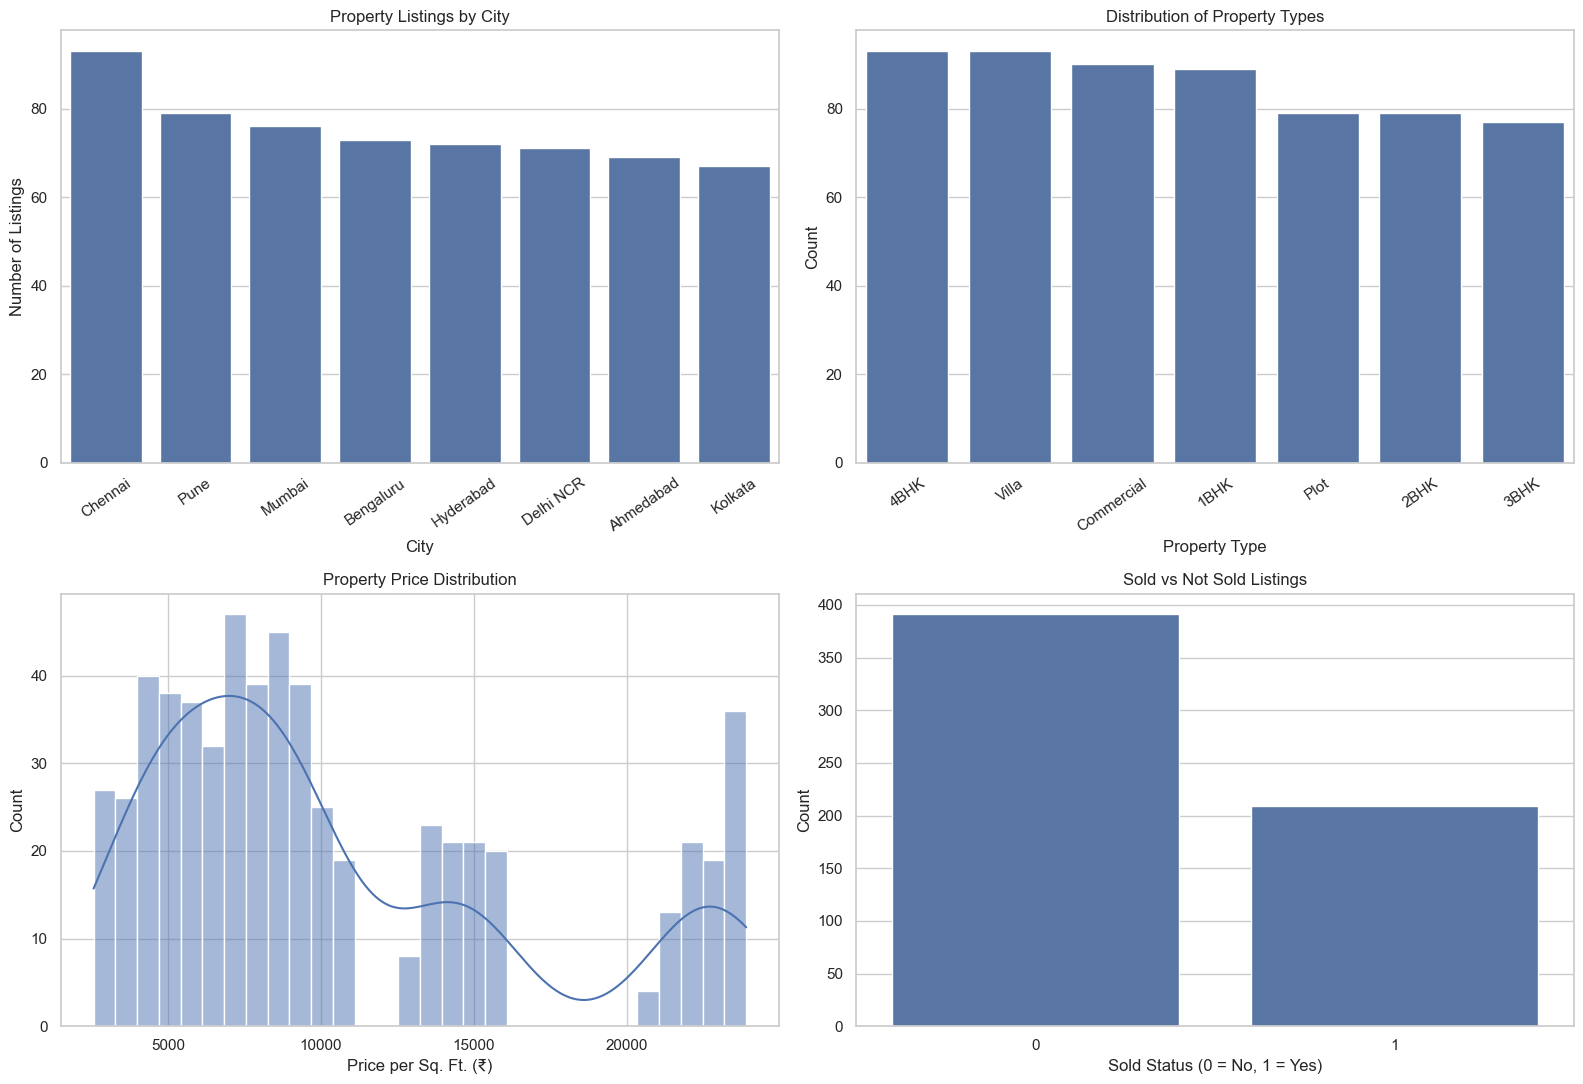

In [4]:
# Exploratory Data Analysis - Visualizations

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Property listings by city
city_counts = df["city"].value_counts()

sns.barplot(
    x=city_counts.index,
    y=city_counts.values,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Property Listings by City")
axes[0, 0].set_xlabel("City")
axes[0, 0].set_ylabel("Number of Listings")
axes[0, 0].tick_params(axis="x", rotation=35)

# 2. Property types
sns.countplot(
    data=df,
    x="type",
    order=df["type"].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Property Types")
axes[0, 1].set_xlabel("Property Type")
axes[0, 1].set_ylabel("Count")
axes[0, 1].tick_params(axis="x", rotation=35)

# 3. Price per square foot distribution
sns.histplot(
    data=df,
    x="price_per_sqft",
    bins=30,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Property Price Distribution")
axes[1, 0].set_xlabel("Price per Sq. Ft. (₹)")

# 4. Sold status
sns.countplot(
    data=df,
    x="sold",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Sold vs Not Sold Listings")
axes[1, 1].set_xlabel("Sold Status (0 = No, 1 = Yes)")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()

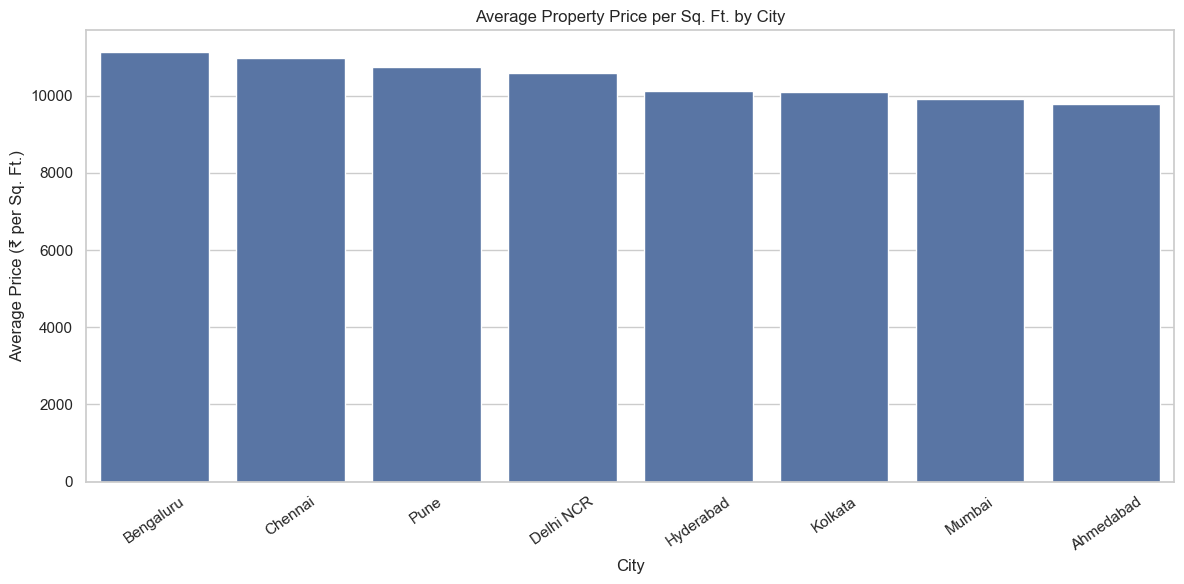

,Average Price per Sq. Ft.
city,
Bengaluru,11135.74
Chennai,10970.89
Pune,10751.90
Delhi NCR,10592.86
Hyderabad,10113.17
Kolkata,10083.51
Mumbai,9903.28
Ahmedabad,9787.78


In [5]:
# Average Property Price by City

city_prices = (
    df.groupby("city")["price_per_sqft"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_prices.index,
    y=city_prices.values
)

plt.title("Average Property Price per Sq. Ft. by City")
plt.xlabel("City")
plt.ylabel("Average Price (₹ per Sq. Ft.)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(city_prices.round(2).to_frame("Average Price per Sq. Ft."))

,total_listings,average_price,average_area,average_days
type,,,,
1BHK,89,5074.15,2192.19,188.30
2BHK,79,7014.43,2326.29,179.56
3BHK,77,9602.13,2141.68,178.88
4BHK,93,14489.65,2191.23,190.08
Commercial,90,8414.48,2165.39,187.64
Plot,79,3913.67,2111.76,183.04
Villa,93,22659.37,2292.11,177.17


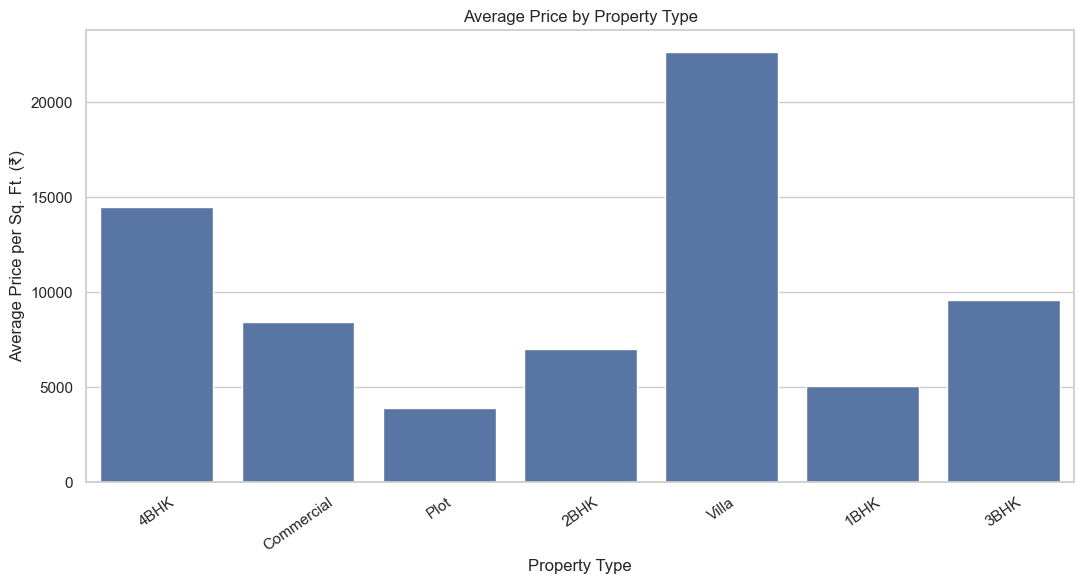

In [6]:
# Average Price by Property Type

type_analysis = df.groupby("type").agg(
    total_listings=("listing_id", "count"),
    average_price=("price_per_sqft", "mean"),
    average_area=("area_sqft", "mean"),
    average_days=("days_on_market", "mean")
).round(2)

display(type_analysis)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=df,
    x="type",
    y="price_per_sqft",
    estimator="mean",
    errorbar=None
)

plt.title("Average Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price per Sq. Ft. (₹)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


,total_listings,average_price,average_area,average_days_on_market,sold_count
transaction_type,,,,,
Rent,137,11124.29,2280.42,188.33,44
Sale,463,10242.80,2181.51,182.33,165


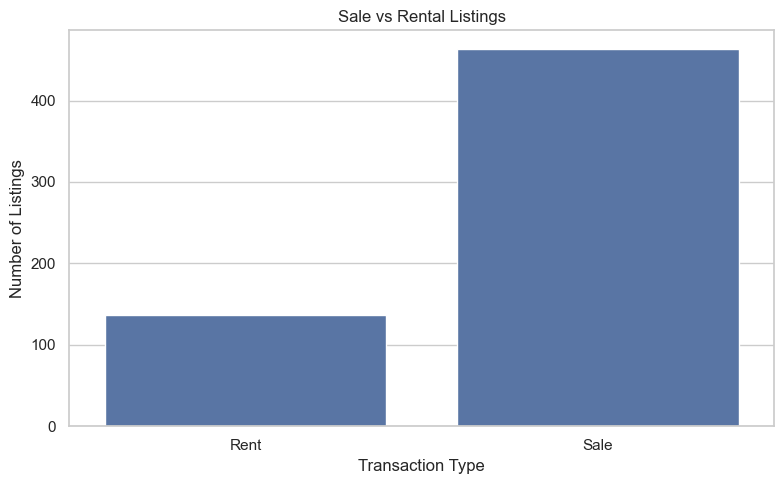

In [7]:
# Transaction Analysis

transaction_summary = df.groupby("transaction_type").agg(
    total_listings=("listing_id", "count"),
    average_price=("price_per_sqft", "mean"),
    average_area=("area_sqft", "mean"),
    average_days_on_market=("days_on_market", "mean"),
    sold_count=("sold", "sum")
).round(2)

display(transaction_summary)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="transaction_type")

plt.title("Sale vs Rental Listings")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

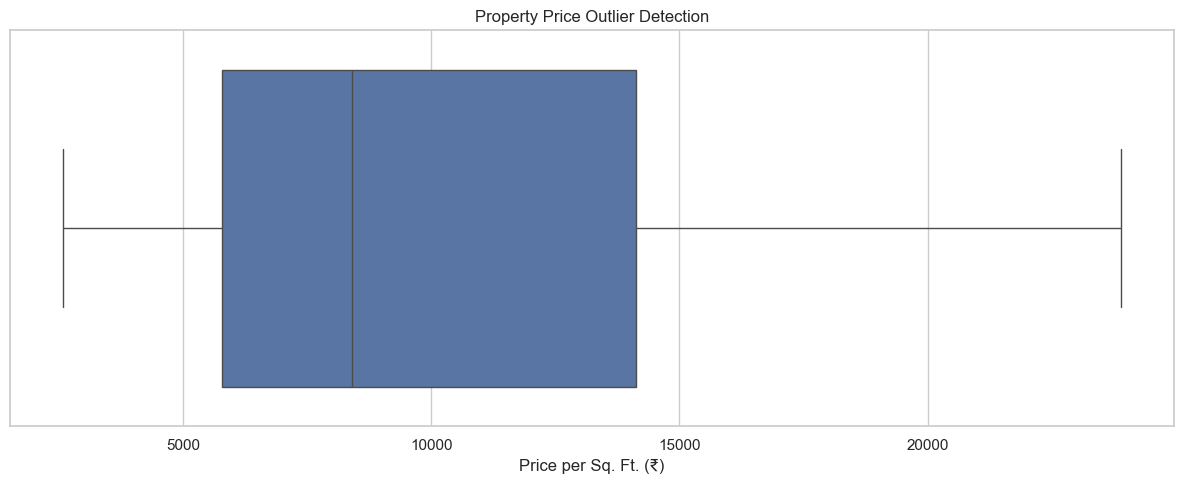

Lower Limit: -6758.375
Upper Limit: 26654.625
Number of Price Outliers: 0


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold


In [8]:
# Price Distribution

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="price_per_sqft"
)

plt.title("Property Price Outlier Detection")
plt.xlabel("Price per Sq. Ft. (₹)")
plt.tight_layout()
plt.show()

# IQR Outlier Detection

Q1 = df["price_per_sqft"].quantile(0.25)
Q3 = df["price_per_sqft"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["price_per_sqft"] < lower_limit) |
    (df["price_per_sqft"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Price Outliers:", len(outliers))

display(outliers.head(10))

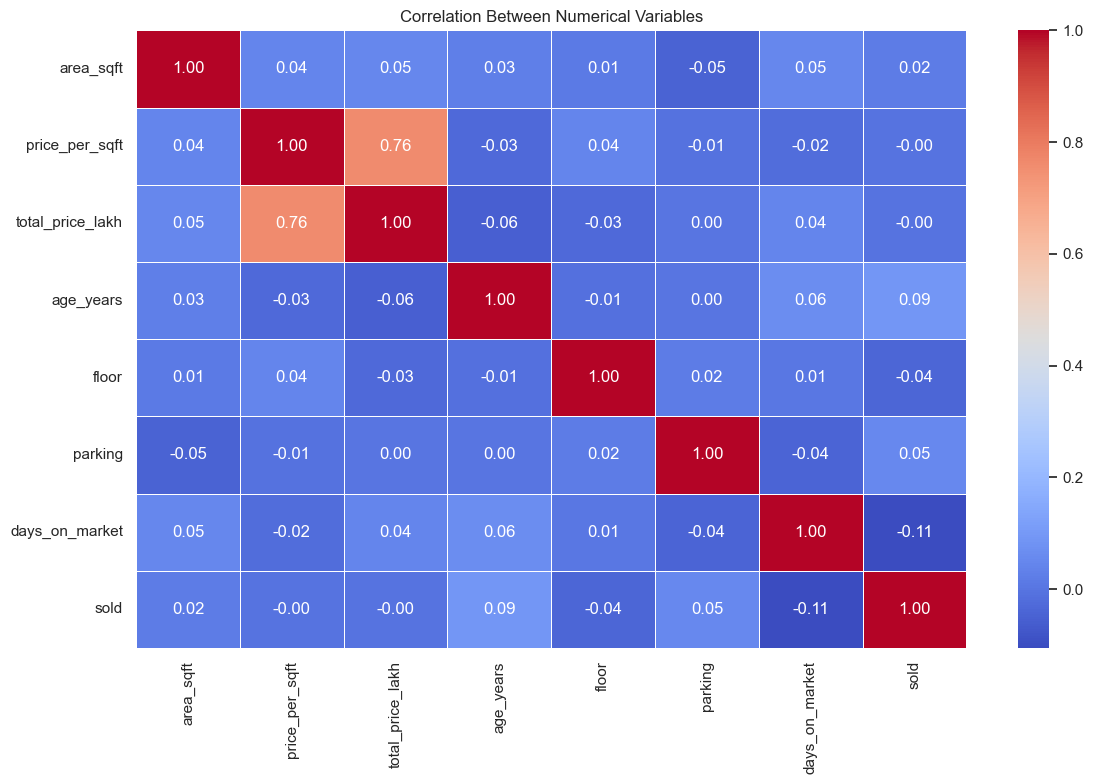

In [9]:
# Numerical Correlation Analysis

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

In [10]:
# Check calculated price against recorded total price

df["calculated_price_lakh"] = (
    df["area_sqft"] * df["price_per_sqft"] / 100000
)

df["price_difference_lakh"] = (
    df["calculated_price_lakh"] - df["total_price_lakh"]
).abs()

print("Average Price Difference:",
      round(df["price_difference_lakh"].mean(), 2), "Lakh")

print("Median Price Difference:",
      round(df["price_difference_lakh"].median(), 2), "Lakh")

print("\nTransaction Type vs Sold Status")

display(pd.crosstab(
    df["transaction_type"],
    df["sold"],
    margins=True
))

print("\nRecords with Largest Price Differences")

display(
    df.sort_values(
        "price_difference_lakh",
        ascending=False
    )[
        [
            "listing_id",
            "city",
            "area_sqft",
            "price_per_sqft",
            "total_price_lakh",
            "price_difference_lakh"
        ]
    ].head(10)
)

Average Price Difference: 120.39 Lakh
Median Price Difference: 87.28 Lakh

Transaction Type vs Sold Status


sold,0,1,All
transaction_type,,,
Rent,93,44,137
Sale,298,165,463
All,391,209,600



Records with Largest Price Differences


,listing_id,city,area_sqft,price_per_sqft,total_price_lakh,price_difference_lakh
503,PROP-0504,Mumbai,722,22325,914.71,753.52350
264,PROP-0265,Mumbai,3519,22934,121.84,685.20746
445,PROP-0446,Mumbai,3932,23017,236.23,668.79844
437,PROP-0438,Mumbai,3519,21332,113.84,636.83308
116,PROP-0117,Bengaluru,437,13400,581.19,522.63200
45,PROP-0046,Delhi NCR,2558,22927,90.73,495.74266
141,PROP-0142,Pune,3752,15770,96.79,494.90040
244,PROP-0245,Ahmedabad,3066,21559,171.53,489.46894
454,PROP-0455,Ahmedabad,412,23395,585.52,489.13260
29,PROP-0030,Pune,3792,23546,418.17,474.69432


In [11]:
# Generate Key Business Insights

highest_city = city_prices.idxmax()
lowest_city = city_prices.idxmin()

most_common_type = df["type"].value_counts().idxmax()

average_price = df["price_per_sqft"].mean()
median_price = df["price_per_sqft"].median()

sold_percentage = df["sold"].mean() * 100

print("========== BUSINESS INSIGHTS ==========")

print(f"Total Properties: {len(df)}")

print(f"Number of Cities: {df['city'].nunique()}")

print(f"Highest Average Price City: {highest_city}")

print(f"Lowest Average Price City: {lowest_city}")

print(f"Most Common Property Type: {most_common_type}")

print(f"Average Price per Sq. Ft.: ₹{average_price:.2f}")

print(f"Median Price per Sq. Ft.: ₹{median_price:.2f}")

print(f"Sold Status Percentage: {sold_percentage:.2f}%")

print(f"Average Days on Market: {df['days_on_market'].mean():.2f}")

print("========================================")

========== BUSINESS INSIGHTS ==========
Total Properties: 600
Number of Cities: 8
Highest Average Price City: Bengaluru
Lowest Average Price City: Ahmedabad
Most Common Property Type: 4BHK
Average Price per Sq. Ft.: ₹10444.07
Median Price per Sq. Ft.: ₹8401.00
Sold Status Percentage: 34.83%
Average Days on Market: 183.70


recommendations = [
    "Compare property prices across cities before making investment decisions.",
    "Investigate high-priced properties to understand premium market segments.",
    "Monitor properties with longer days on market to identify slower-moving inventory.",
    "Use property type and locality analysis to improve pricing strategies.",
    "Verify inconsistencies between calculated and recorded property values.",
    "Clarify the meaning of the sold status for rental listings before using it as a sales KPI."
]

print("========== BUSINESS RECOMMENDATIONS ==========")

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

# Conclusion

The exploratory data analysis examined 600 real-estate listings across eight Indian cities.

The analysis covered property prices, property types, city-wise distribution, transaction categories, sale status, price distributions, outliers and numerical correlations.

The dataset contains no missing values or duplicate records. However, the analysis identified discrepancies between calculated property values and recorded total prices. The meaning of the sold-status field for rental listings also requires clarification.

The findings can support property-market comparisons, pricing analysis and business decision-making. Further validation is recommended before using the dataset for financial or investment decisions.

In [13]:
# Business Summary Dashboard

summary = pd.DataFrame({
    "Metric": [
        "Total Listings",
        "Total Cities",
        "Average Price per Sq. Ft.",
        "Median Price per Sq. Ft.",
        "Average Property Area",
        "Average Days on Market",
        "Sold Listings",
        "Price Outliers"
    ],
    "Value": [
        len(df),
        df["city"].nunique(),
        round(df["price_per_sqft"].mean(), 2),
        round(df["price_per_sqft"].median(), 2),
        round(df["area_sqft"].mean(), 2),
        round(df["days_on_market"].mean(), 2),
        int(df["sold"].sum()),
        len(outliers)
    ]
})

display(summary)

,Metric,Value
0,Total Listings,600.00
1,Total Cities,8.00
2,Average Price per Sq. Ft.,10444.07
3,Median Price per Sq. Ft.,8401.00
4,Average Property Area,2204.09
5,Average Days on Market,183.70
6,Sold Listings,209.00
7,Price Outliers,0.00


In [14]:
# Export Analysis Results

output_folder = "eda_outputs"

import os
os.makedirs(output_folder, exist_ok=True)

city_prices.to_csv(
    f"{output_folder}/city_price_analysis.csv"
)

type_analysis.to_csv(
    f"{output_folder}/property_type_analysis.csv"
)

transaction_summary.to_csv(
    f"{output_folder}/transaction_analysis.csv"
)

summary.to_csv(
    f"{output_folder}/business_summary.csv",
    index=False
)

print("EDA results exported successfully!")

EDA results exported successfully!


In [15]:
Q1 = df["price_per_sqft"].quantile(0.25)
Q3 = df["price_per_sqft"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["price_per_sqft"] < lower_limit) |
    (df["price_per_sqft"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Actual Outlier Count:", len(outliers))

Lower Limit: -6758.375
Upper Limit: 26654.625
Actual Outlier Count: 0


In [16]:
import os

for file in os.listdir("eda_outputs"):
    print(file)

business_summary.csv
city_price_analysis.csv
property_type_analysis.csv
transaction_analysis.csv


In [4]:
# W8D5 - Data Quality Validation

import pandas as pd
import numpy as np

# Dataset overview
print("DATASET OVERVIEW")
print("-" * 40)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print("Total duplicates:", df.duplicated().sum())

# Data types
print("\nDATA TYPES")
print(df.dtypes)

# Numerical summary
print("\nNUMERICAL SUMMARY")
print(df.describe())

# Validation summary
quality_report = pd.DataFrame({
    "Check": [
        "Missing Values",
        "Duplicate Rows",
        "Empty Dataset"
    ],
    "Result": [
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        df.empty
    ]
})

display(quality_report)

DATASET OVERVIEW
----------------------------------------
Rows: 600
Columns: 15

MISSING VALUES
listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64

DUPLICATE RECORDS
Total duplicates: 0

DATA TYPES
listing_id              str
city                    str
locality                str
type                    str
area_sqft             int64
price_per_sqft        int64
total_price_lakh    float64
age_years             int64
floor                 int64
parking               int64
furnished               str
listed_date             str
days_on_market        int64
transaction_type        str
sold                  int64
dtype: object

NUMERICAL SUMMARY
         area_sqft  price_per_sqft  total_price_lakh   ag

,Check,Result
0,Missing Values,0
1,Duplicate Rows,0
2,Empty Dataset,False


In [5]:
# W8D5 - Data Quality Validation

import pandas as pd
import numpy as np

# Dataset overview
print("DATASET OVERVIEW")
print("-" * 40)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print("Total duplicates:", df.duplicated().sum())

# Data types
print("\nDATA TYPES")
print(df.dtypes)

# Numerical summary
print("\nNUMERICAL SUMMARY")
print(df.describe())

# Validation summary
quality_report = pd.DataFrame({
    "Check": [
        "Missing Values",
        "Duplicate Rows",
        "Empty Dataset"
    ],
    "Result": [
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        df.empty
    ]
})

display(quality_report)

DATASET OVERVIEW
----------------------------------------
Rows: 600
Columns: 15

MISSING VALUES
listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64

DUPLICATE RECORDS
Total duplicates: 0

DATA TYPES
listing_id              str
city                    str
locality                str
type                    str
area_sqft             int64
price_per_sqft        int64
total_price_lakh    float64
age_years             int64
floor                 int64
parking               int64
furnished               str
listed_date             str
days_on_market        int64
transaction_type        str
sold                  int64
dtype: object

NUMERICAL SUMMARY
         area_sqft  price_per_sqft  total_price_lakh   ag

,Check,Result
0,Missing Values,0
1,Duplicate Rows,0
2,Empty Dataset,False


In [6]:
# W8D5 - Business Insights Summary

print("BUSINESS INSIGHTS")
print("=" * 45)

print("\n1. CITY PERFORMANCE")
print(df.groupby("city")["total_price_lakh"].mean()
      .sort_values(ascending=False))

print("\n2. PROPERTY TYPE PERFORMANCE")
print(df.groupby("type")["total_price_lakh"].mean()
      .sort_values(ascending=False))

print("\n3. TRANSACTION DISTRIBUTION")
print(df["transaction_type"].value_counts())

print("\n4. SALES STATUS")
print(df["sold"].value_counts())

print("\n5. MARKET DURATION")
print("Average days on market:",
      round(df["days_on_market"].mean(), 2))

print("\n6. AVERAGE PROPERTY PRICE")
print("₹", round(df["total_price_lakh"].mean(), 2), "Lakh")

BUSINESS INSIGHTS

1. CITY PERFORMANCE
city
Bengaluru    267.768767
Chennai      250.960860
Pune         237.941139
Hyderabad    236.931111
Delhi NCR    221.323239
Kolkata      218.444627
Mumbai       208.807368
Ahmedabad    181.123043
Name: total_price_lakh, dtype: float64

2. PROPERTY TYPE PERFORMANCE
type
Villa         502.212581
4BHK          331.909140
3BHK          217.951429
Commercial    181.582889
2BHK          137.298354
1BHK          105.543146
Plot           82.550759
Name: total_price_lakh, dtype: float64

3. TRANSACTION DISTRIBUTION
transaction_type
Sale    463
Rent    137
Name: count, dtype: int64

4. SALES STATUS
sold
0    391
1    209
Name: count, dtype: int64

5. MARKET DURATION
Average days on market: 183.7

6. AVERAGE PROPERTY PRICE
₹ 229.1 Lakh


In [7]:
# W8D5 - Business Summary Report

city_summary = df.groupby("city")["total_price_lakh"].mean()
property_summary = df.groupby("type")["total_price_lakh"].mean()

report = {
    "Total Properties": len(df),
    "Average Property Price (Lakh)": round(df["total_price_lakh"].mean(), 2),
    "Average Market Duration (Days)": round(df["days_on_market"].mean(), 2),
    "Highest Average Price City": city_summary.idxmax(),
    "Highest Average Price (Lakh)": round(city_summary.max(), 2),
    "Most Expensive Property Type": property_summary.idxmax(),
    "Highest Property Type Average (Lakh)": round(property_summary.max(), 2),
    "Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Rows": int(df.duplicated().sum())
}

business_report = pd.DataFrame(
    list(report.items()),
    columns=["Metric", "Value"]
)

display(business_report)

# Save report
business_report.to_csv(
    "w8d5_business_summary.csv",
    index=False
)

print("Business summary saved successfully.")

,Metric,Value
0,Total Properties,600
1,Average Property Price (Lakh),229.1
2,Average Market Duration (Days),183.7
3,Highest Average Price City,Bengaluru
4,Highest Average Price (Lakh),267.77
5,Most Expensive Property Type,Villa
6,Highest Property Type Average (Lakh),502.21
7,Missing Values,0
8,Duplicate Rows,0


Business summary saved successfully.


In [8]:
# W8D5 - Business Summary Report

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("week-8-day-5-ai-data-platform/eda/eda_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

city_summary = df.groupby("city")["total_price_lakh"].mean()
property_summary = df.groupby("type")["total_price_lakh"].mean()

report = {
    "Total Properties": len(df),
    "Average Property Price (Lakh)": round(df["total_price_lakh"].mean(), 2),
    "Average Market Duration (Days)": round(df["days_on_market"].mean(), 2),
    "Highest Average Price City": city_summary.idxmax(),
    "Highest Average Price (Lakh)": round(city_summary.max(), 2),
    "Lowest Average Price City": city_summary.idxmin(),
    "Lowest Average Price (Lakh)": round(city_summary.min(), 2),
    "Most Expensive Property Type": property_summary.idxmax(),
    "Highest Property Type Average (Lakh)": round(property_summary.max(), 2),
    "Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Rows": int(df.duplicated().sum())
}

business_report = pd.DataFrame(
    list(report.items()),
    columns=["Metric", "Value"]
)

display(business_report)

business_report.to_csv(
    OUTPUT_DIR / "w8d5_business_summary.csv",
    index=False
)

print("W8D5 business summary exported successfully.")

,Metric,Value
0,Total Properties,600
1,Average Property Price (Lakh),229.1
2,Average Market Duration (Days),183.7
3,Highest Average Price City,Bengaluru
4,Highest Average Price (Lakh),267.77
5,Lowest Average Price City,Ahmedabad
6,Lowest Average Price (Lakh),181.12
7,Most Expensive Property Type,Villa
8,Highest Property Type Average (Lakh),502.21
9,Missing Values,0


W8D5 business summary exported successfully.


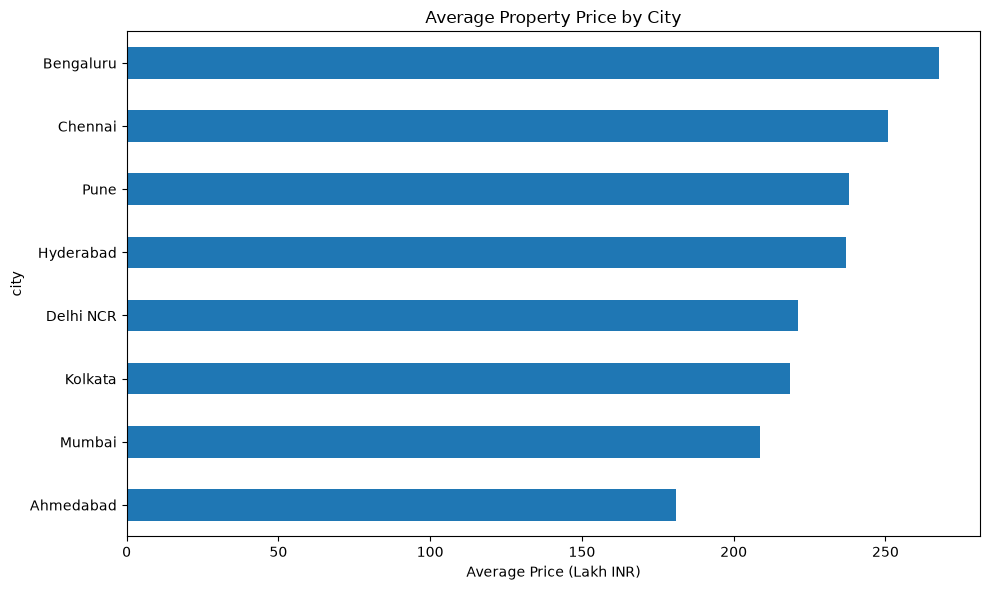

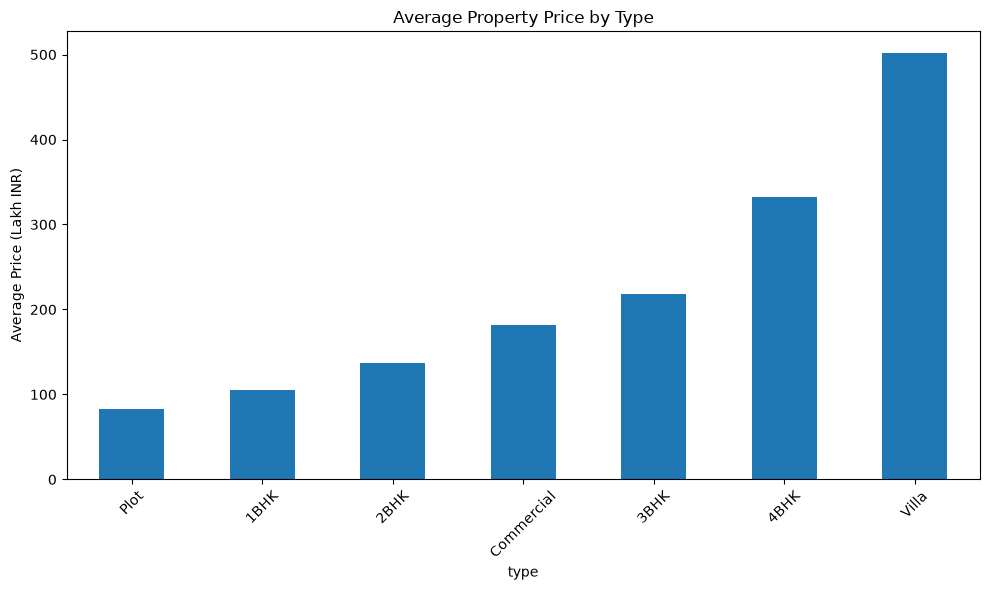

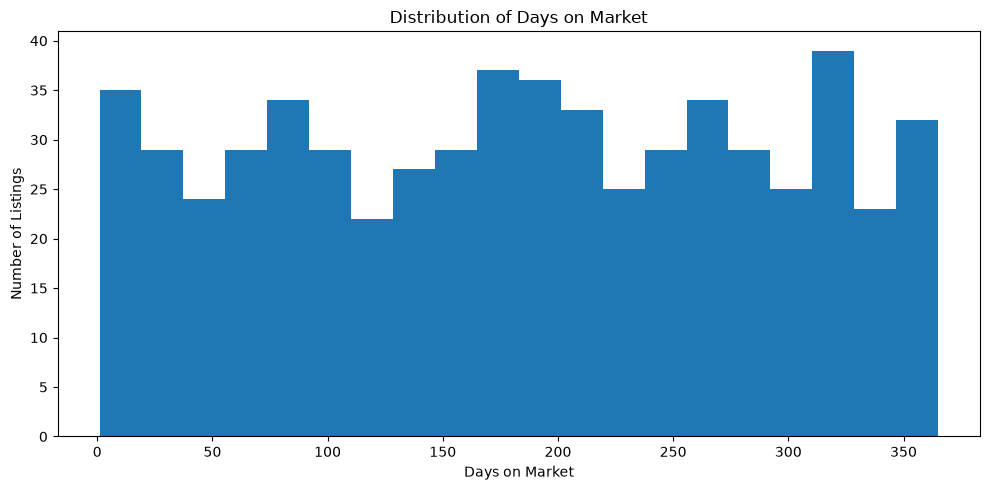

Three charts generated and saved.


In [9]:
# W8D5 - Business Data Visualizations

import matplotlib.pyplot as plt
from pathlib import Path

CHART_DIR = Path("week-8-day-5-ai-data-platform/eda/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

# City-wise average property price
city_prices = df.groupby("city")["total_price_lakh"].mean().sort_values()

plt.figure(figsize=(10, 6))
city_prices.plot(kind="barh")
plt.title("Average Property Price by City")
plt.xlabel("Average Price (Lakh INR)")
plt.tight_layout()
plt.savefig(CHART_DIR / "city_average_prices.png", dpi=150)
plt.show()
plt.close()

# Property type comparison
type_prices = df.groupby("type")["total_price_lakh"].mean().sort_values()

plt.figure(figsize=(10, 6))
type_prices.plot(kind="bar")
plt.title("Average Property Price by Type")
plt.ylabel("Average Price (Lakh INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(CHART_DIR / "property_type_prices.png", dpi=150)
plt.show()
plt.close()

# Market duration distribution
plt.figure(figsize=(10, 5))
plt.hist(df["days_on_market"], bins=20)
plt.title("Distribution of Days on Market")
plt.xlabel("Days on Market")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.savefig(CHART_DIR / "market_duration.png", dpi=150)
plt.show()
plt.close()

print("Three charts generated and saved.")

In [10]:
# W8D5 - Final Output Verification

from pathlib import Path

required_outputs = [
    Path("week-8-day-5-ai-data-platform/eda/eda_outputs/w8d5_business_summary.csv"),
    Path("week-8-day-5-ai-data-platform/eda/charts/city_average_prices.png"),
    Path("week-8-day-5-ai-data-platform/eda/charts/property_type_prices.png"),
    Path("week-8-day-5-ai-data-platform/eda/charts/market_duration.png")
]

for file in required_outputs:
    print(
        f"{'PASS' if file.exists() else 'FAIL'}: {file}"
    )

assert all(file.exists() for file in required_outputs), (
    "Some expected outputs are missing."
)

print("\nW8D5 output verification completed.")

PASS: week-8-day-5-ai-data-platform\eda\eda_outputs\w8d5_business_summary.csv
PASS: week-8-day-5-ai-data-platform\eda\charts\city_average_prices.png
PASS: week-8-day-5-ai-data-platform\eda\charts\property_type_prices.png
PASS: week-8-day-5-ai-data-platform\eda\charts\market_duration.png

W8D5 output verification completed.
